# Catchment geometry analysis: Teno (CT-5, CT-7) and Lontué (CT-6, CT-1)

Purpose: quantify how catchment geometry differs between the Teno and Lontué tributaries (Reviewer 2, Round 2):
(1) trunk-channel valley-floor width; (2) lowland (Central Depression proxy) area; (3) lowland area in the nested upstream
catchments CT-1 and CT-7; (4) hillslope-angle distributions; (5) width functions and planform shape metrics.

Valley floors are cells with height above nearest drainage (HAND) at or below a threshold and slope at or below a threshold;
widths are measured on transects perpendicular to each trunk channel.

**Inputs** (single-band GeoTIFFs on an identical grid): DEM (m) and binary catchment masks for CT-5 and CT-6 (1 = inside).
The CRS is read from the DEM. Nested sample sites CT-1 and CT-7 are given as UTM 19S coordinates (Section 8).

**Outputs**: `valley_width_transects.csv`, `valley_width_by_reach.csv`, `catchment_lowland_summary.csv`,
`nested_catchment_summary.csv`, `hillslope_angle_summary.csv`, `width_function_summary.csv`, `width_function.csv`,
`valley_floor_QC.png`, `hillslope_angle_histograms.png`, `width_functions.png`.

**Dependencies**: numpy, scipy, rasterio, pysheds, numba, pandas, matplotlib.

In [1]:
# ---------------------------------------------------------------- parameters
DATA_DIR  = '../data/dem/'        # folder with dem data
DEM_PATH  = DATA_DIR + 'dem_utm30m.tif'      # filled DEM (m); edit paths as needed
MASK_TENO = DATA_DIR + 'CT_5_mask'           # CT-5 (Teno) catchment mask
MASK_LONT = DATA_DIR + 'CT_6_mask'           # CT-6 (Lontue) catchment mask

A_CHANNEL = 5e6                   # channel-initiation drainage area (m^2) used as the HAND reference network
A_TRUNK_MIN = 50e6                # trunk tracing stops where drainage area falls below this (m^2)
THRESHOLDS = [(5,5),(10,5),(10,10),(20,10)]   # (HAND max in m, slope max in degrees); (10,5) is the reference case
SPACING  = 1000.                  # transect spacing along the trunk (m)
HALF_LEN = 4000.                  # transect half-length (m); runs reaching the end are reported as unbounded (NaN)
STEP     = 5.                     # sampling step along a transect (m)
DIR_WIN  = 20                     # +/- cells along the trunk used to estimate local channel direction
BANDS    = [(0,20),(20,40),(40,60),(60,150)]  # distance bands upstream of the sample (km)
LOWLAND_Z = 500.                  # elevation (m) used as a proxy for the Central Depression boundary
EPS      = 1e-4                   # elevation increment (m) for epsilon depression filling
PAD      = 20                     # padding (cells) around the mask bounding box when cropping

# ---------------------------------------------------------------- nested catchments (Section 8)
# Sample sites in WGS 84 / UTM 19S (m), converted from samples.kml (EPSG:4326 -> EPSG:32719).
NESTED_SITES = {'CT-1 (upper Lontue)':(313940.4,6096220.8), 'CT-7 (upper Teno)':(333232.2,6125037.0)}
SNAP_RADIUS  = 5                  # cells; site is snapped to the highest-accumulation cell within this radius

# ---------------------------------------------------------------- hillslope angles (Section 9)
SLOPE_THRESH = [25.,30.,35.]      # slope classes (degrees) reported as fraction of catchment area

# ---------------------------------------------------------------- width function (Section 10)
WF_BIN_KM = 1.0                   # flow-distance bin width for the width function (km)

In [2]:
import numpy as np
if not hasattr(np,'in1d'): np.in1d=np.isin          # pysheds 0.5 calls np.in1d, removed in numpy 2.x
import heapq, rasterio, pandas as pd, matplotlib.pyplot as plt
from rasterio.windows import Window
from scipy import ndimage
from numba import njit
from pysheds.grid import Grid

## 1. Crop DEM and masks to the two catchments

In [3]:
# Read masks on the full grid and find their joint bounding box.
with rasterio.open(MASK_TENO) as r: m5_full=r.read(1)>0
with rasterio.open(MASK_LONT) as r: m6_full=r.read(1)>0
rows,cols=np.where(m5_full|m6_full)
r0,r1=max(rows.min()-PAD,0),rows.max()+PAD
c0,c1=max(cols.min()-PAD,0),cols.max()+PAD
win=Window(c0,r0,c1-c0+1,r1-r0+1)

# Read the DEM inside the window; carry its CRS and transform forward to the intermediate raster
with rasterio.open(DEM_PATH) as r:
    dem=r.read(1,window=win).astype(np.float64)
    T=r.window_transform(win)
    DX=abs(r.res[0])                                   # grid spacing (m)
    CRS=r.crs                                          # CRS taken from the source file, not assigned
print('source CRS:',CRS)
m5=m5_full[r0:r1+1,c0:c1+1]; m6=m6_full[r0:r1+1,c0:c1+1]   # masks cropped to the same window
CELL_KM2=DX*DX/1e6                                     # cell area (km^2)

# NaN cells (no data) are set high so they cannot capture flow; check they lie outside both catchments.
nan=np.isnan(dem)
print('grid spacing (m):',round(DX,2),'| crop shape:',dem.shape,'| NaN cells inside masks:',int((nan&(m5|m6)).sum()))
dem[nan]=1e4
print('CT-5 area (km2):',round(m5.sum()*CELL_KM2,1),'| CT-6 area (km2):',round(m6.sum()*CELL_KM2,1))

source CRS: PROJCS["WGS 84 / UTM zone 19S",GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-69],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
grid spacing (m): 26.57 | crop shape: (3262, 3493) | NaN cells inside masks: 0
CT-5 area (km2): 1495.6 | CT-6 area (km2): 2573.0


ERROR 1: PROJ: internal_proj_identify: /Users/Glong1/anaconda3/share/proj/proj.db lacks DATABASE.LAYOUT.VERSION.MAJOR / DATABASE.LAYOUT.VERSION.MINOR metadata. It comes from another PROJ installation.


## 2. Epsilon depression filling
The supplied DEM is filled, but large flats (e.g., reservoirs, flat valley floors) leave undefined D8 directions. A priority-flood
fill with a small elevation increment (Barnes et al., 2014) gives every cell a strictly lower downstream neighbour.

In [4]:
@njit
def priority_flood_eps(z, eps):
    nr,nc=z.shape
    out=z.copy(); closed=np.zeros((nr,nc),np.bool_)
    h=[(0.0,0,0)]; h.pop()                              # typed empty heap for numba
    for r in range(nr):                                 # seed with grid-edge cells (outflow boundary)
        for c in range(nc):
            if r==0 or c==0 or r==nr-1 or c==nc-1:
                heapq.heappush(h,(out[r,c],r,c)); closed[r,c]=True
    while len(h)>0:                                     # always expand the lowest open cell
        e,r,c=heapq.heappop(h)
        for dr in (-1,0,1):
            for dc in (-1,0,1):
                rr=r+dr; cc=c+dc
                if rr<0 or cc<0 or rr>=nr or cc>=nc or closed[rr,cc]: continue
                closed[rr,cc]=True
                if out[rr,cc]<=e+eps: out[rr,cc]=e+eps  # raise to just above the spill elevation
                heapq.heappush(h,(out[rr,cc],rr,cc))
    return out

dem_eps=priority_flood_eps(dem,EPS)
raise_m=dem_eps-dem
print('max elevation change inside catchments (m):',round(float(raise_m[m5|m6].max()),4))

max elevation change inside catchments (m): 94.0201


## 3. Flow routing, accumulation, and HAND

In [5]:
# pysheds reads from file, so write the filled DEM to a temporary GeoTIFF.
prof=dict(driver='GTiff',height=dem.shape[0],width=dem.shape[1],count=1,dtype='float64',crs=CRS,transform=T)
with rasterio.open('_dem_eps.tif','w',**prof) as w: w.write(dem_eps,1)
grid=Grid.from_raster('_dem_eps.tif'); g_dem=grid.read_raster('_dem_eps.tif')
fdir=grid.flowdir(g_dem)                                # D8, ESRI codes 1,2,4,...,128
acc_r=grid.accumulation(fdir)                          # upstream cell count (pysheds Raster)
chan=acc_r>(A_CHANNEL/(DX*DX))                          # reference channel network for HAND (kept as Raster)
acc=np.asarray(acc_r,dtype=np.float64)
hand=np.asarray(grid.compute_hand(fdir,g_dem,chan),dtype=np.float64)  # height above nearest drainage (m)
fdir=np.asarray(fdir)

# Verification: drainage area at each catchment outlet should equal the mask area.
for name,m in [('CT-5',m5),('CT-6',m6)]:
    print(name,'mask area (km2):',round(m.sum()*CELL_KM2,1),'| routed outlet area (km2):',round(np.where(m,acc,0).max()*CELL_KM2,1))

/Users/Glong1/anaconda3/lib/python3.11/site-packages/pysheds/io.py:134: UserWarning: No `nodata` value detected. Defaulting to 0.
  warnings.warn('No `nodata` value detected. Defaulting to 0.')
/Users/Glong1/anaconda3/lib/python3.11/site-packages/pysheds/io.py:134: UserWarning: No `nodata` value detected. Defaulting to 0.
  warnings.warn('No `nodata` value detected. Defaulting to 0.')


CT-5 mask area (km2): 1495.6 | routed outlet area (km2): 1495.5
CT-6 mask area (km2): 2573.0 | routed outlet area (km2): 2573.1


## 4. Trunk channels

In [6]:
D8={1:(0,1),2:(1,1),4:(1,0),8:(1,-1),16:(0,-1),32:(-1,-1),64:(-1,0),128:(-1,1)}

def upstream_cells(r,c):
    # Neighbours whose D8 direction points into (r,c).
    out=[]
    for code,(dr,dc) in D8.items():
        rr,cc=r-dr,c-dc
        if 0<=rr<acc.shape[0] and 0<=cc<acc.shape[1] and fdir[rr,cc]==code: out.append((rr,cc))
    return out

def trace_trunk(r,c):
    # From the outlet, repeatedly step to the upstream neighbour with the largest drainage area.
    path=[(r,c)]
    while True:
        u=upstream_cells(r,c)
        if not u: break
        r,c=max(u,key=lambda p:acc[p])
        if acc[r,c]*DX*DX<A_TRUNK_MIN: break
        path.append((r,c))
    return np.array(path)

def distance_along(path):
    # Cumulative distance upstream of the outlet (m); diagonal steps count sqrt(2)*DX.
    return np.concatenate([[0],np.cumsum(np.hypot(*np.diff(path,axis=0).T)*DX)])

trunks={}
for name,m in [('Teno',m5),('Lontue',m6)]:
    outlet=np.unravel_index(np.where(m,acc,0).argmax(),acc.shape)  # outlet = sample site
    trunks[name]=trace_trunk(*outlet)
    print(name,'trunk length (km):',round(distance_along(trunks[name])[-1]/1e3,1))

Teno trunk length (km): 124.4
Lontue trunk length (km): 138.1


## 5. Valley floor and transect widths

In [7]:
gy,gx=np.gradient(dem,DX)
slope=np.degrees(np.arctan(np.hypot(gx,gy)))           # local slope (degrees)

def valley_floor(H,S):
    # Valley floor: HAND <= H and slope <= S; a 1-cell opening removes isolated cells.
    return ndimage.binary_opening((hand<=H)&(slope<=S))

def transect_widths(path,vf):
    # Width of the contiguous valley-floor run containing the channel cell, on transects normal to the channel.
    s=distance_along(path); k=np.arange(-HALF_LEN,HALF_LEN+STEP,STEP)/DX; c0=k.size//2; rows=[]
    for t in np.arange(SPACING/2,s[-1]-SPACING/2,SPACING):
        i=np.searchsorted(s,t)
        a,b=max(i-DIR_WIN,0),min(i+DIR_WIN,len(path)-1)
        d=(path[b]-path[a]).astype(float); d/=np.hypot(*d)
        n=np.array([-d[1],d[0]])                       # unit normal to local channel direction (row,col)
        rr=np.round(path[i][0]+k*n[0]).astype(int); cc=np.round(path[i][1]+k*n[1]).astype(int)
        ok=(rr>=0)&(cc>=0)&(rr<vf.shape[0])&(cc<vf.shape[1])
        v=np.zeros(k.size,bool); v[ok]=vf[rr[ok],cc[ok]]
        w=np.nan
        if v[c0]:
            lo=c0
            while lo>0 and v[lo-1]: lo-=1
            hi=c0
            while hi<k.size-1 and v[hi+1]: hi+=1
            if lo>0 and hi<k.size-1: w=(hi-lo+1)*STEP  # NaN if the run reaches the transect end (unbounded)
        rows.append(dict(dist_km=t/1e3,width_m=w,area_km2=acc[tuple(path[i])]*CELL_KM2))
    return pd.DataFrame(rows)

tr=[]
for H,S in THRESHOLDS:
    vf=valley_floor(H,S)
    for name,p in trunks.items():
        df=transect_widths(p,vf); df.insert(0,'river',name); df.insert(1,'HAND_m',H); df.insert(2,'slope_deg',S); tr.append(df)
tr=pd.concat(tr,ignore_index=True)
tr.to_csv('valley_width_transects.csv',index=False)

## 6. Summary tables

In [8]:
# Median width by distance band; n counts bounded transects only.
rows=[]
for (river,H,S),g in tr.groupby(['river','HAND_m','slope_deg']):
    for a,b in BANDS:
        x=g[(g.dist_km>=a)&(g.dist_km<b)].width_m.dropna()
        rows.append(dict(river=river,HAND_m=H,slope_deg=S,band_km=f'{a}-{b}',median_width_m=round(x.median()) if len(x) else np.nan,
                         p25_m=round(x.quantile(.25)) if len(x) else np.nan,p75_m=round(x.quantile(.75)) if len(x) else np.nan,n=len(x)))
by_reach=pd.DataFrame(rows); by_reach.to_csv('valley_width_by_reach.csv',index=False)
print(by_reach.pivot_table(index=['HAND_m','slope_deg','band_km'],columns='river',values='median_width_m'))

# Catchment-scale lowland area (proxy for Central Depression), reference valley-floor area, mean slope.
vf_ref=valley_floor(10,5); rows=[]
for name,m in [('Teno (CT-5)',m5),('Lontue (CT-6)',m6)]:
    low=m&(dem<LOWLAND_Z)
    rows.append(dict(catchment=name,area_km2=round(m.sum()*CELL_KM2,1),
                     lowland_km2=round(low.sum()*CELL_KM2,1),lowland_pct=round(100*low.sum()/m.sum(),1),
                     valley_floor_km2=round((vf_ref&m).sum()*CELL_KM2,1),valley_floor_lowland_km2=round((vf_ref&low).sum()*CELL_KM2,1),
                     mean_slope_deg=round(slope[m].mean(),1)))
lowland=pd.DataFrame(rows); lowland.to_csv('catchment_lowland_summary.csv',index=False); lowland

river                     Lontue    Teno
HAND_m slope_deg band_km                
5      5         0-20      530.0   585.0
                 20-40     342.0   510.0
                 40-60     195.0   415.0
                 60-150    138.0   160.0
10     5         0-20     1670.0   988.0
                 20-40     695.0   948.0
                 40-60     412.0   642.0
                 60-150    160.0   230.0
       10        0-20     1780.0  1122.0
                 20-40     728.0  1022.0
                 40-60     410.0   662.0
                 60-150    130.0   235.0
20     10        0-20     2358.0  1050.0
                 20-40    1130.0  1900.0
                 40-60     680.0  1072.0
                 60-150    130.0   275.0


,catchment,area_km2,lowland_km2,lowland_pct,valley_floor_km2,valley_floor_lowland_km2,mean_slope_deg
0,Teno (CT-5),1495.6,84.0,5.6,64.5,42.1,24.3
1,Lontue (CT-6),2573.0,518.2,20.1,213.2,181.2,16.9


## 7. QC figure

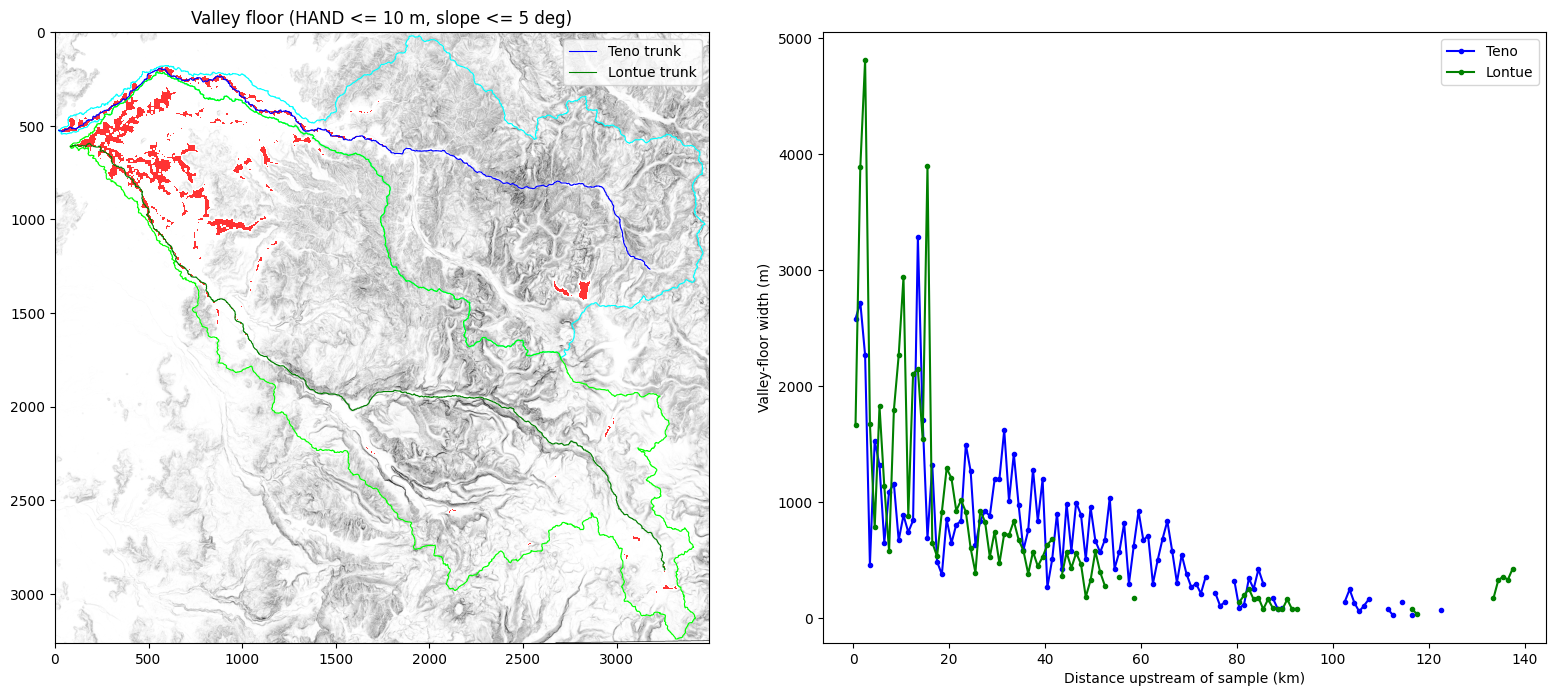

In [9]:
fig,ax=plt.subplots(1,2,figsize=(16,7))
ax[0].imshow(np.cos(np.radians(slope)),cmap='gray',vmin=0.3,vmax=1)          # slope shading as base map
ax[0].imshow(np.ma.masked_where(~(vf_ref&(m5|m6)),vf_ref),cmap='autumn',alpha=0.8)  # reference valley floor
ax[0].contour(m5,[0.5],colors='cyan',linewidths=0.8); ax[0].contour(m6,[0.5],colors='lime',linewidths=0.8)
for name,c in [('Teno','b'),('Lontue','g')]:
    p=trunks[name]; ax[0].plot(p[:,1],p[:,0],c,lw=0.8,label=name+' trunk')
    g=tr[(tr.river==name)&(tr.HAND_m==10)&(tr.slope_deg==5)]
    ax[1].plot(g.dist_km,g.width_m,c+'o-',ms=3,label=name)
ax[0].legend(); ax[0].set_title('Valley floor (HAND <= 10 m, slope <= 5 deg)')
ax[1].set_xlabel('Distance upstream of sample (km)'); ax[1].set_ylabel('Valley-floor width (m)'); ax[1].legend()
plt.tight_layout(); plt.savefig('valley_floor_QC.png',dpi=110); plt.show()

## 8. Nested upstream catchments (CT-1, CT-7)
Delineates the catchments of the upstream samples and reports their lowland area. If CT-1 drains no lowland yet records a low
erosion rate, the low Lontué rate is not produced by its lowland valleys. The flow-distance routine below is reused in Section 10.

In [10]:
# D8 offsets indexed by ESRI direction code, as arrays for numba.
CODES=np.array([1,2,4,8,16,32,64,128]); DR=np.array([0,1,1,1,0,-1,-1,-1]); DC=np.array([1,1,0,-1,-1,-1,0,1])
LUT_R=np.zeros(129,np.int64); LUT_C=np.zeros(129,np.int64); VALID=np.zeros(129,np.bool_)
for k,dr,dc in zip(CODES,DR,DC): LUT_R[k]=dr; LUT_C[k]=dc; VALID[k]=True

# Cells sorted by decreasing accumulation: every downstream cell precedes all of its upstream cells.
ORDER=np.argsort(-acc,axis=None)

@njit
def flow_distance(fd,order,orow,ocol,dx,lut_r,lut_c,valid):
    # Flow-path distance (m) from every cell to the outlet (orow,ocol); NaN for cells not draining to it.
    nr,nc=fd.shape; dist=np.full((nr,nc),np.nan); dist[orow,ocol]=0.0
    for idx in order:
        r=idx//nc; c=idx%nc
        if r==orow and c==ocol: continue
        k=fd[r,c]
        if k<0 or k>128 or not valid[k]: continue
        rr=r+lut_r[k]; cc=c+lut_c[k]
        if rr<0 or cc<0 or rr>=nr or cc>=nc: continue
        if not np.isnan(dist[rr,cc]):                       # downstream cell drains to the outlet
            step=dx*1.4142135623730951 if (lut_r[k]!=0 and lut_c[k]!=0) else dx
            dist[r,c]=dist[rr,cc]+step
    return dist

def snap(x,y):
    # Convert map coordinates to row/col in the cropped grid, then move to the max-accumulation cell nearby.
    col=int((x-T.c)/T.a); row=int((y-T.f)/T.e)
    r0_,c0_=max(row-SNAP_RADIUS,0),max(col-SNAP_RADIUS,0)
    w=acc[r0_:row+SNAP_RADIUS+1,c0_:col+SNAP_RADIUS+1]
    i,j=np.unravel_index(w.argmax(),w.shape)
    return r0_+i,c0_+j

fd_i=fdir.astype(np.int64)
catch={'CT-5 (lower Teno)':m5,'CT-6 (lower Lontue)':m6}
rows=[]
for name,(x,y) in NESTED_SITES.items():
    r,c=snap(x,y)
    m=~np.isnan(flow_distance(fd_i,ORDER,r,c,DX,LUT_R,LUT_C,VALID)); catch[name]=m
    low=m&(dem<LOWLAND_Z)
    rows.append(dict(catchment=name,area_km2=round(m.sum()*CELL_KM2,1),lowland_km2=round(low.sum()*CELL_KM2,1),
                     lowland_pct=round(100*low.sum()/m.sum(),1)))
nested=pd.DataFrame(rows); nested.to_csv('nested_catchment_summary.csv',index=False)
nested   # verify areas against Table 1 (CT-1 ~1420 km2, CT-7 ~1207 km2)

,catchment,area_km2,lowland_km2,lowland_pct
0,CT-1 (upper Lontue),1386.0,0.0,0.0
1,CT-7 (upper Teno),1207.5,0.0,0.0


## 9. Hillslope-angle distributions
Fraction of catchment area at or above threshold slopes, the area susceptible to stochastic landsliding (cf. the mean-basin-slope
control on replicability reported by Sosa Gonzalez et al., 2017). Slopes from a 26.6 m DEM underestimate true hillslope angles,
so the values are comparative between catchments, not absolute.

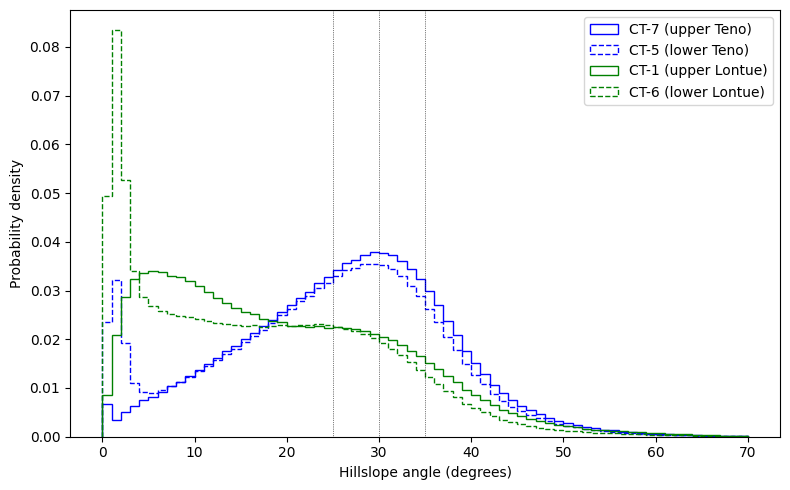

,catchment,mean_deg,median_deg,p90_deg,pct_ge_25deg,pct_ge_30deg,pct_ge_35deg
0,CT-7 (upper Teno),26.5,27.1,39.8,57.5,39.4,21.6
1,CT-5 (lower Teno),24.3,25.6,38.7,51.8,34.5,18.3
2,CT-1 (upper Lontue),19.6,17.7,37.0,33.3,22.3,12.9
3,CT-6 (lower Lontue),16.9,15.4,34.2,28.0,17.2,8.9


In [11]:
order_names=['CT-7 (upper Teno)','CT-5 (lower Teno)','CT-1 (upper Lontue)','CT-6 (lower Lontue)']
rows=[]
for name in order_names:
    s=slope[catch[name]]
    row=dict(catchment=name,mean_deg=round(s.mean(),1),median_deg=round(np.median(s),1),p90_deg=round(np.percentile(s,90),1))
    for th in SLOPE_THRESH: row[f'pct_ge_{int(th)}deg']=round(100*(s>=th).mean(),1)
    rows.append(row)
hs=pd.DataFrame(rows); hs.to_csv('hillslope_angle_summary.csv',index=False)

fig,ax=plt.subplots(figsize=(8,5)); bins=np.arange(0,71,1)
for name,c,ls in zip(order_names,['b','b','g','g'],['-','--','-','--']):
    ax.hist(slope[catch[name]],bins=bins,density=True,histtype='step',color=c,ls=ls,label=name)
for th in SLOPE_THRESH: ax.axvline(th,color='k',lw=0.5,ls=':')
ax.set_xlabel('Hillslope angle (degrees)'); ax.set_ylabel('Probability density'); ax.legend()
plt.tight_layout(); plt.savefig('hillslope_angle_histograms.png',dpi=110); plt.show()
hs

## 10. Width functions and planform shape
The width function is the catchment area per unit flow distance to the outlet; its shape is a geometric proxy for how
synchronously a storm is delivered to the outlet. Shape metrics: maximum flow length L, form factor A/L² (Horton, 1932), and
elongation ratio 2√(A/π)/L (Schumm, 1956), here using flow length rather than straight-line basin length.

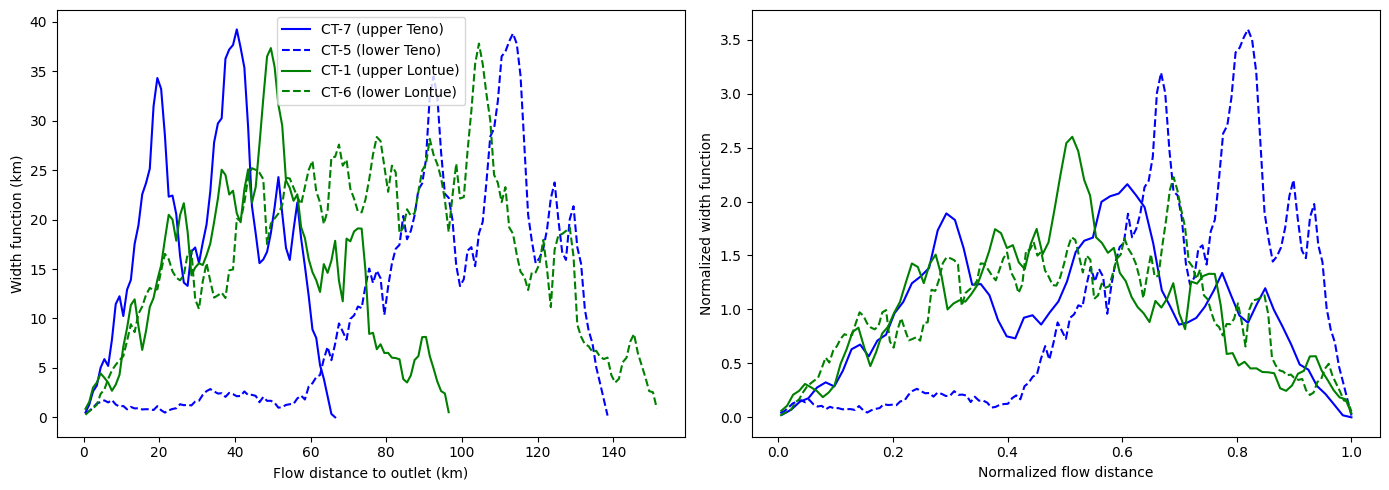

,catchment,area_km2,max_flow_length_km,mean_flow_distance_km,mean_over_max,form_factor,elongation_ratio,peak_width_km,peak_dist_km
0,CT-7 (upper Teno),1207.5,66.1,34.3,0.52,0.277,0.59,39.2,40.5
1,CT-5 (lower Teno),1495.6,138.9,98.1,0.71,0.078,0.31,38.8,113.5
2,CT-1 (upper Lontue),1386.0,96.5,47.1,0.49,0.149,0.44,37.3,49.5
3,CT-6 (lower Lontue),2573.0,151.7,76.8,0.51,0.112,0.38,37.8,104.5


In [12]:
rows=[]; wf=[]
for name in order_names:
    m=catch[name]
    o=np.unravel_index(np.where(m,acc,0).argmax(),acc.shape)              # outlet = max accumulation in catchment
    d=flow_distance(fd_i,ORDER,o[0],o[1],DX,LUT_R,LUT_C,VALID)/1e3         # flow distance (km)
    d=d[m & ~np.isnan(d)]
    A=m.sum()*CELL_KM2; L=d.max()
    edges=np.arange(0,L+WF_BIN_KM,WF_BIN_KM); h,_=np.histogram(d,bins=edges)
    w=h*CELL_KM2/WF_BIN_KM                                                 # width function (km^2 per km = km)
    wf.append(pd.DataFrame(dict(catchment=name,dist_km=edges[:-1]+WF_BIN_KM/2,width_km=w)))
    rows.append(dict(catchment=name,area_km2=round(A,1),max_flow_length_km=round(L,1),mean_flow_distance_km=round(d.mean(),1),
                     mean_over_max=round(d.mean()/L,2),form_factor=round(A/L**2,3),elongation_ratio=round(2*np.sqrt(A/np.pi)/L,2),
                     peak_width_km=round(w.max(),1),peak_dist_km=round(edges[w.argmax()]+WF_BIN_KM/2,1)))
wfs=pd.DataFrame(rows); wfs.to_csv('width_function_summary.csv',index=False)
wf=pd.concat(wf,ignore_index=True); wf.to_csv('width_function.csv',index=False)

fig,ax=plt.subplots(1,2,figsize=(14,5))
for name,c,ls in zip(order_names,['b','b','g','g'],['-','--','-','--']):
    g=wf[wf.catchment==name]
    ax[0].plot(g.dist_km,g.width_km,c,ls=ls,label=name)                                   # absolute
    L=g.dist_km.max(); A=g.width_km.sum()*WF_BIN_KM
    ax[1].plot(g.dist_km/L,g.width_km*L/A,c,ls=ls,label=name)                            # normalized by L and A
ax[0].set_xlabel('Flow distance to outlet (km)'); ax[0].set_ylabel('Width function (km)')
ax[1].set_xlabel('Normalized flow distance'); ax[1].set_ylabel('Normalized width function')
ax[0].legend(); plt.tight_layout(); plt.savefig('width_functions.png',dpi=110); plt.show()
wfs

In [13]:
# Contributing area within given flow distances of each sample site (uses the width functions from Section 10)
DIST_KM=[20,40,60]                                        # flow-distance thresholds (km)
rows=[]
for name in order_names:
    g=wf[wf.catchment==name]; A=g.width_km.sum()*WF_BIN_KM   # total catchment area (km^2)
    for D in DIST_KM:
        a=g[g.dist_km<D].width_km.sum()*WF_BIN_KM            # area within D km of the outlet (km^2)
        rows.append(dict(catchment=name,within_km=D,area_km2=round(a,1),pct=round(100*a/A,1)))
near=pd.DataFrame(rows); near.to_csv('near_outlet_area.csv',index=False)
near.pivot(index='within_km',columns='catchment',values='area_km2')

catchment,CT-1 (upper Lontue),CT-5 (lower Teno),CT-6 (lower Lontue),CT-7 (upper Teno)
within_km,,,,
20,132.6,21.5,132.9,266.5
40,516.5,55.6,415.8,745.2
60,1025.2,92.6,863.8,1178.9


In [14]:
# ---------------------------------------------------------------- Table S6: catchment geometry summary
# Assembles one row per catchment from Sections 6, 8, 9 and 10. Run after all previous cells.
# Valley-floor widths are medians for the reference threshold (HAND <= 10 m, slope <= 5 deg), with the
# range of medians across all thresholds in parentheses; reported for the trunk channels upstream of CT-5 and CT-6 only.
REF=(10,5)                                                    # reference (HAND m, slope deg)
NEAR_KM=[20,40,60]                                            # flow-distance thresholds (km)
trunk_of={'CT-5 (lower Teno)':'Teno','CT-6 (lower Lontue)':'Lontue'}

rows=[]
for name in order_names:
    m=catch[name]; A=m.sum()*CELL_KM2
    low=(m&(dem<LOWLAND_Z)).sum()*CELL_KM2                    # area below the lowland elevation proxy (km^2)
    s=slope[m]
    row={'Catchment':name,
         'Area (km2)':round(A),
         f'Area below {int(LOWLAND_Z)} m (km2, %)':f'{low:.0f} ({100*low/A:.0f})',
         'Mean slope (deg)':round(s.mean(),1),
         'Area >= 30 deg (%)':round(100*(s>=30).mean(),1)}
    g=wf[wf.catchment==name]                                  # width function from Section 10
    for D in NEAR_KM:
        a=g[g.dist_km<D].width_km.sum()*WF_BIN_KM             # area within D km flow distance of the sample (km^2)
        row[f'Area within {D} km of sample (km2, %)']=f'{a:.0f} ({100*a/A:.0f})'
    for a_,b_ in BANDS:                                       # trunk valley-floor width by reach
        key=f'Valley-floor width {a_}-{b_} km (m)'
        if name in trunk_of:
            br=by_reach[(by_reach.river==trunk_of[name])&(by_reach.band_km==f'{a_}-{b_}')]
            ref=br[(br.HAND_m==REF[0])&(br.slope_deg==REF[1])].median_width_m.iloc[0]
            row[key]=f'{ref:.0f} ({br.median_width_m.min():.0f}-{br.median_width_m.max():.0f})'
        else:
            row[key]='-'                                      # widths not measured for nested catchments
    rows.append(row)

tableS6=pd.DataFrame(rows).set_index('Catchment').T          # catchments as columns, metrics as rows
tableS6.to_csv('Table_S6_catchment_geometry.csv')
tableS6

Catchment,CT-7 (upper Teno),CT-5 (lower Teno),CT-1 (upper Lontue),CT-6 (lower Lontue)
Area (km2),1208,1496,1386,2573
"Area below 500 m (km2, %)",0 (0),84 (6),0 (0),518 (20)
Mean slope (deg),26.5,24.3,19.6,16.9
Area >= 30 deg (%),39.4,34.5,22.3,17.2
"Area within 20 km of sample (km2, %)",266 (22),21 (1),133 (10),133 (5)
"Area within 40 km of sample (km2, %)",745 (62),56 (4),517 (37),416 (16)
"Area within 60 km of sample (km2, %)",1179 (98),93 (6),1025 (74),864 (34)
Valley-floor width 0-20 km (m),-,988 (585-1122),-,1670 (530-2358)
Valley-floor width 20-40 km (m),-,948 (510-1900),-,695 (342-1130)
Valley-floor width 40-60 km (m),-,642 (415-1072),-,412 (195-680)
